In [206]:
import json

import matplotlib.pyplot as plt
import pandas as pd
import s3fs
import seaborn as sns

fs = s3fs.S3FileSystem(
    endpoint_url="https://minio.lab.sspcloud.fr",
    client_kwargs={"region_name": "us-east-1"},
)

# Utils

In [152]:
def fetch_data(year):
    extraction_evo_path = f"s3://mateomorin/legifrance/extraction/contingent_evolution/year={year}/extraction_{year}.parquet"
    extraction_path = f"s3://mateomorin/legifrance/extraction/contingent_old/year={year}/extraction_{year}.parquet"
    metadata_path = f"s3://mateomorin/legifrance/metadata/acco_metadata_{year}.parquet"

    extraction_evo = pd.read_parquet(extraction_evo_path, filesystem=fs)
    extraction = pd.read_parquet(extraction_path, filesystem=fs)
    metadata = pd.read_parquet(metadata_path, filesystem=fs)

    return extraction, extraction_evo, metadata

In [ ]:
def treat_extraction(extraction, extraction_evo):
    print(f"Nombre d'erreurs dans extraction: {extraction['erreur'].count()}/{len(extraction)}")
    print(f"Nombre d'erreurs dans extraction_evo: {extraction_evo['erreur'].count()}/{len(extraction)}")
    extraction = extraction[pd.col("erreur").isna()]
    extraction_evo = extraction_evo[pd.col("erreur").isna()]

    compare_extraction = extraction_evo.merge(extraction, on="reference", how="inner", suffixes=["_evo", ""])

    mask_presence = pd.col("presence_contingent_conventionnel_evo") | pd.col("presence_contingent_conventionnel")
    compare_extraction = compare_extraction[mask_presence]

    mask_mismatch = pd.col("presence_contingent_conventionnel_evo") ^ pd.col("presence_contingent_conventionnel")
    mismatches = compare_extraction[mask_mismatch]

    print(f"Nombre de contingents mesurés dans extraction: {compare_extraction['presence_contingent_conventionnel'].sum()}")
    print(f"Nombre de contingents mesurés dans extraction_evo: {compare_extraction['presence_contingent_conventionnel_evo'].sum()}")
    print(f"Nombre d'observations différentes sur la présence d'un contingent: {len(mismatches)}")

    removed_other_text = mismatches.loc[pd.col("presence_contingent_conventionnel"), "reference"].to_list()

    removed_anon = mismatches[pd.col("presence_contingent_conventionnel_evo")]
    pattern = r"(?i)\b(?:" \
        r"cach[ée]e?|dissimul[ée]e?|laiss[ée]e?\s+blanche?|masqu[ée]e?|occult[ée]e?|effac[ée]e?|" \
        r"placeholder|tiret|n/a|na|none|null|unspecified|blank|" \
        r"non\s+sp[ée]cifi[ée]e?|non\s+mentionn[ée]e?|non\s+fourni[ée]e?|non\s+communiqu[ée]e?|non\s+trouv[ée]e?|non\s+disponible|non\s+pr[ée]cis[ée]e?|" \
        r"pas\s+de\s+donn[ée]e?s?|donn[ée]e?\s+manquante?|aucune?\s+information|information\s+absente|" \
        r"non\s+applicable|non\s+renseign[ée]e?|introuvable|inconnu[ee]?s?|" \
        r"pas\s+mentionn[ée]e?|pas\s+sp[ée]cifi[ée]e?" \
        r")\b"
    removed_anon = removed_anon[pd.col("justification_ou_reserve_evo").str.contains(pattern, na=False)]
    removed_anon = removed_anon["reference"].to_list()

    removed_recall = mismatches[pd.col("presence_contingent_conventionnel_evo")]
    removed_recall = removed_recall[pd.col("justification_ou_reserve").str.contains("rappel", na=False)]
    removed_recall = removed_recall["reference"].to_list()

    removed = list(set(removed_other_text + removed_anon + removed_recall))

    extraction_evo = extraction_evo[pd.col("presence_contingent_conventionnel")]
    extraction_filtered = extraction_evo[~pd.col("reference").isin(removed)]
    print(f"""{len(removed)} observations filtrées:
    - {len(removed_other_text)} fixent un accord tiré d'un autre texte légal
    - {len(removed_anon)} ont une donnée manquante qui a été interprétée comme présente par Qwen
    - {len(removed_recall)} rappellent un contingent sans le fixer dans l'accord
    """)

    citation_anon = mismatches[pd.col("reference").isin(removed_anon)]["citation_exacte_evo"].to_list()
    
    print("Citation des extraits supposés anonymisés :")
    for i, citation in enumerate(citation_anon):
        print(f"{i}. {citation}")

    print("")
    print("Références anonymisées (dans le même ordre) :")
    for i, ref in enumerate(removed_anon):
        print(f"{i}. {ref}")

    return extraction_filtered, removed_anon

In [138]:
def add_correct_references(extraction_filtered, extraction, references_to_add):
    new_references = set(references_to_add) - set(extraction_filtered["reference"].to_list())
    new_lines = extraction[pd.col("reference").isin(new_references)]

    return pd.concat([extraction_filtered, new_lines])

In [139]:
def develop_contingents(df):
    initial_len = len(df)
    print("Taille iniale :", initial_len)
    if initial_len == 0:
        return df
    df = df.copy()

    # Convert to correct dtype
    if isinstance(df.dtypes["contingents"], pd.StringDtype):
        contingents = df["contingents"].to_list()
        contingents = [json.loads(chaine) for chaine in contingents]
        df["contingents"] = contingents

    df = df.explode("contingents")
    df_dict = pd.json_normalize(df["contingents"])
    df = pd.concat([df.drop(columns=["contingents"]), df_dict], axis=1)
    print("Taille finale :", len(df))
    return df

In [140]:
def distrib_contingent(extraction_developped):
    # Contingent mensuel → annuel
    extraction_developped.loc[pd.col("periode").str.contains("mensuel"), "nombre_heures_fixe"] *= 12
    extraction_developped.loc[pd.col("periode").str.contains("mensuel"), "periode"] = "anuelle (montant à chaque mois x 12)"

    # Définition des bornes de 50 à 600 avec un pas de 25
    bins = range(0, 625, 1)

    plt.figure(figsize=(10, 5))

    # Filtrage entre 50 et 600 h et tracé de l'histogramme
    data = extraction_developped.query("0 <= nombre_heures_fixe <= 600")["nombre_heures_fixe"]

    data.hist(
        bins=bins,
        color="#2b5c8f",
        grid=True,
    )

    plt.title("Répartition des contingents annuels d'heures supplémentaires", fontsize=13, fontweight="bold", pad=12)
    plt.xlabel("Nombre d'heures", labelpad=8)
    plt.ylabel("Nombre de contingents mentionnés", labelpad=8)
    plt.xticks(range(0, 625, 50))
    plt.yticks(range(50, 700, 50))
    plt.grid(alpha=0.5, linestyle="--")
    plt.tight_layout()
    plt.show()

In [141]:
def distrib_type_substitution(extraction_developped):
    data = extraction_developped["type_substitution"].value_counts().sort_values(ascending=True)

    _, ax = plt.subplots(figsize=(10, 5))

    # Personnalisation des barres
    bars = ax.barh(data.index, data.values, color="#3498db", height=0.6, alpha=0.85)

    # Ajout des valeurs exactes au bout de chaque barre
    for bar in bars:
        width = bar.get_width()
        ax.text(width + 15, bar.get_y() + bar.get_height()/2, f'{int(width)}', 
                va='center', ha='left', fontsize=10, fontweight='bold', color='#2c3e50')

    # Esthétique générale
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_color('#bdc3c7')
    ax.spines['bottom'].set_color('#bdc3c7')

    # Titre et labels
    ax.set_title("Répartition des types de substitution", fontsize=14, fontweight='bold', pad=20, loc='left', color='#2c3e50')
    ax.set_xlabel("Nombre d'occurrences", fontsize=11, color='#34495e', labelpad=10)

    # Grille légère en arrière-plan uniquement sur l'axe X
    ax.xaxis.grid(True, linestyle='--', alpha=0.5, color='#bdc3c7')
    ax.set_axisbelow(True)

    # Ajustement des marges
    plt.tight_layout()

    # Affichage
    plt.show()

# Résultats par année

### 2018

In [153]:
extraction, extraction_evo, metadata = fetch_data(2018)

In [154]:
extraction_filtered, removed_anon = treat_extraction(extraction, extraction_evo)

Nombre d'erreurs dans extraction: 0/2127
Nombre d'erreurs dans extraction_evo: 0/2127
Nombre de contingents mesurés dans extraction: 912
Nombre de contingents mesurés dans extraction_evo: 907
Nombre d'observations différentes sur la présence d'un contingent: 119
84 observations filtrées:
      - 62 fixent un accord tiré d'un autre texte légal
      - 3 ont une donnée manquante qui a été interprétée comme présente par Qwen
      - 19 rappellent un contingent sans le fixer dans l'accord
      
Citation des extraits supposés anonymisés :
0. Le contingent annuel d’heures supplémentaires pour le personnel sédentaire est maintenu à XXX heures de temps de travail effectif par année civile.
1. **Article 1/ Contingent annuel d’heures supplémentaires**
Le contingent annuel d’heures supplémentaires librement utilisable est fixé à XXXXXXXXXXXX heures.
2. Le contingent annuel d’heures supplémentaires fixé par la Convention collective de la Maintenance, distribution et location de matériels agricole

In [155]:
with fs.open("s3://mateomorin/legifrance/extraction/contingent_evolution/year=2018/anonymised_ref.txt", "w") as f:
    f.write("")

In [25]:
extraction_developped = develop_contingents(extraction_filtered)

Taille iniale : 885
Taille finale : 911


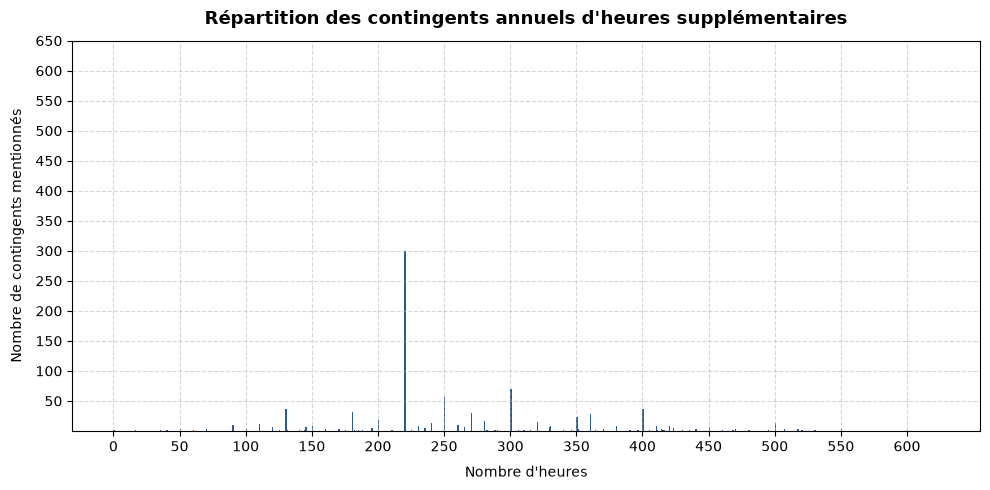

In [26]:
distrib_contingent(extraction_developped)

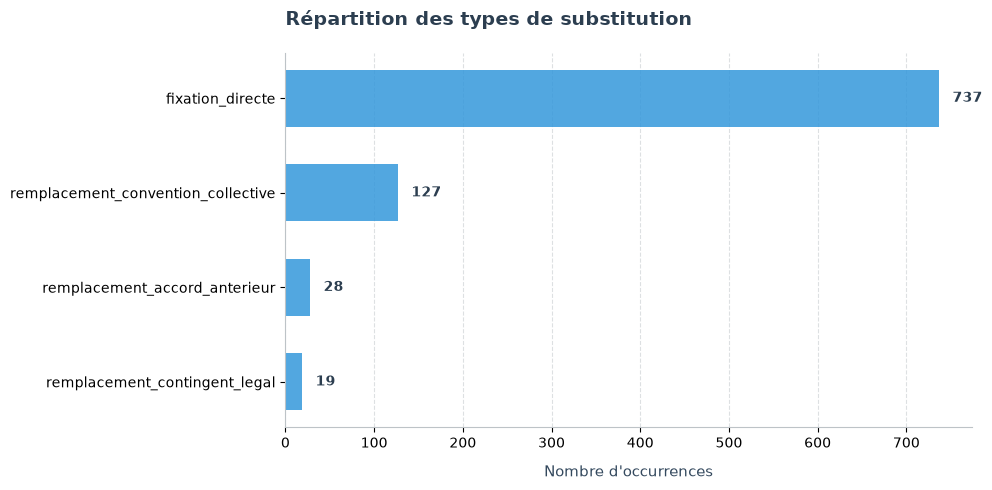

In [27]:
distrib_type_substitution(extraction_developped)

### 2019

In [156]:
extraction, extraction_evo, metadata = fetch_data(2019)

In [157]:
extraction_filtered, removed_anon = treat_extraction(extraction, extraction_evo)

Nombre d'erreurs dans extraction: 0/3056
Nombre d'erreurs dans extraction_evo: 0/3056
Nombre de contingents mesurés dans extraction: 1723
Nombre de contingents mesurés dans extraction_evo: 1725
Nombre d'observations différentes sur la présence d'un contingent: 144
92 observations filtrées:
      - 71 fixent un accord tiré d'un autre texte légal
      - 4 ont une donnée manquante qui a été interprétée comme présente par Qwen
      - 17 rappellent un contingent sans le fixer dans l'accord
      
Citation des extraits supposés anonymisés :
0. Le contingent d’heures supplémentaires est fixé à XXX heures par salarié et par année civile du 1er janvier au 31 décembre.
1. Le contingent d’heures supplémentaires sera désormais fixé à heures par année civile et par salarié. D’un commun accord entre les parties, il a été expressément convenu que ce nouveau contingent sera applicable à l’année 2019 qui est en cours
2. Par dérogation à l'article 9.1.3.2 de la CCN des laboratoires extra-hospitaliers 

In [158]:
extraction_filtered = add_correct_references(extraction_filtered, extraction_evo, removed_anon[3])

In [159]:
with fs.open("s3://mateomorin/legifrance/extraction/contingent_evolution/year=2019/anonymised_ref.txt", "w") as f:
    f.write(removed_anon[3])

In [31]:
extraction_developped = develop_contingents(extraction_filtered)

Taille iniale : 1704
Taille finale : 1749


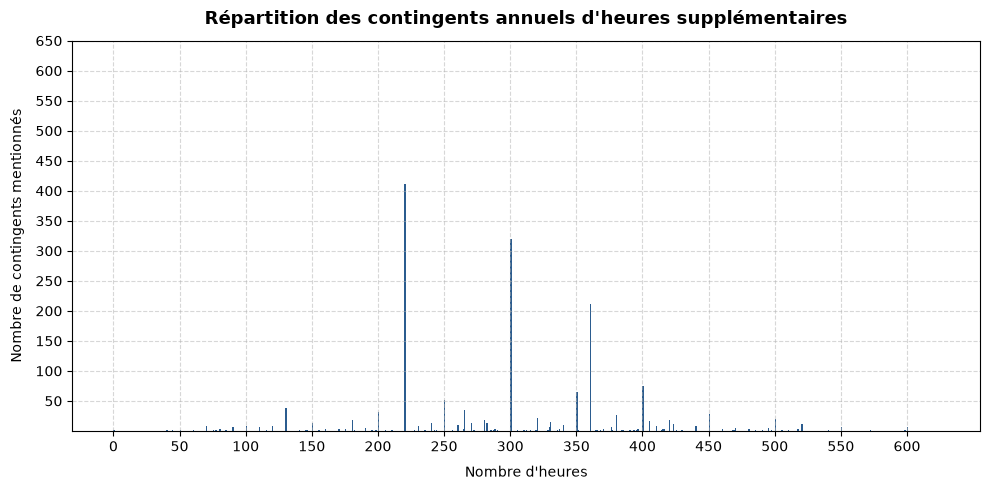

In [32]:
distrib_contingent(extraction_developped)

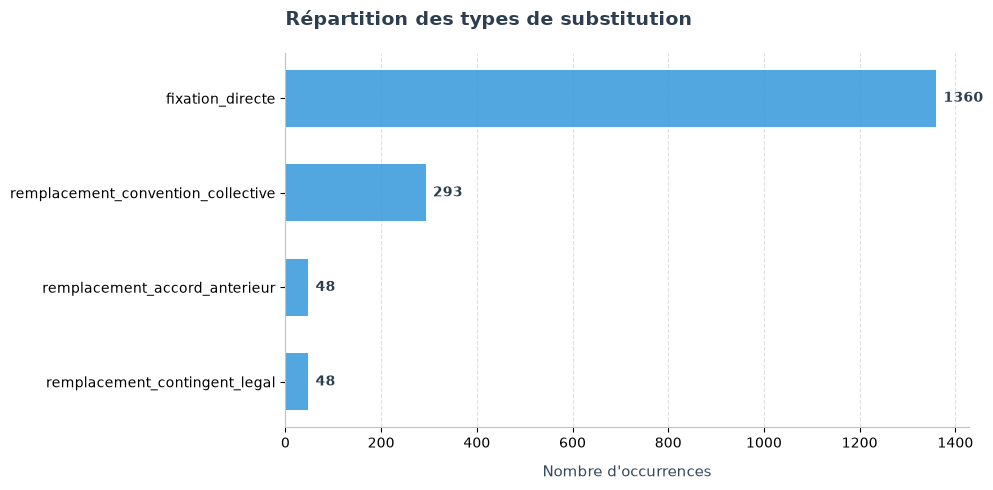

In [33]:
distrib_type_substitution(extraction_developped)

### 2020

In [160]:
extraction, extraction_evo, metadata = fetch_data(2020)

In [161]:
extraction_filtered, removed_anon = treat_extraction(extraction, extraction_evo)

Nombre d'erreurs dans extraction: 0/2745
Nombre d'erreurs dans extraction_evo: 0/2745
Nombre de contingents mesurés dans extraction: 1590
Nombre de contingents mesurés dans extraction_evo: 1545
Nombre d'observations différentes sur la présence d'un contingent: 125
96 observations filtrées:
      - 85 fixent un accord tiré d'un autre texte légal
      - 4 ont une donnée manquante qui a été interprétée comme présente par Qwen
      - 7 rappellent un contingent sans le fixer dans l'accord
      
Citation des extraits supposés anonymisés :
0. D'un commun accord entre les parties signataires, le contingent annuel d'heures supplémentaires est fixé pour l'année 2020 à hauteur de 220 heures par salarié.
1. Par dérogation aux dispositions de l’avenant n°50 du 17 février 2003 étendu par arrêté du 7 juillet 2003 (JO 18 juillet 2003) de la Convention Collective Nationale du Commerce de Détail des fruits, légumes, épicerie et produits laitiers du 15 avril 1988, et conformément aux dispositions de l

In [162]:
extraction_filtered = add_correct_references(extraction_filtered, extraction_evo, removed_anon)

In [164]:
with fs.open("s3://mateomorin/legifrance/extraction/contingent_evolution/year=2020/anonymised_ref.txt", "w") as f:
    f.write("\n".join(removed_anon))

In [37]:
extraction_developped = develop_contingents(extraction_filtered)

Taille iniale : 1538
Taille finale : 1597


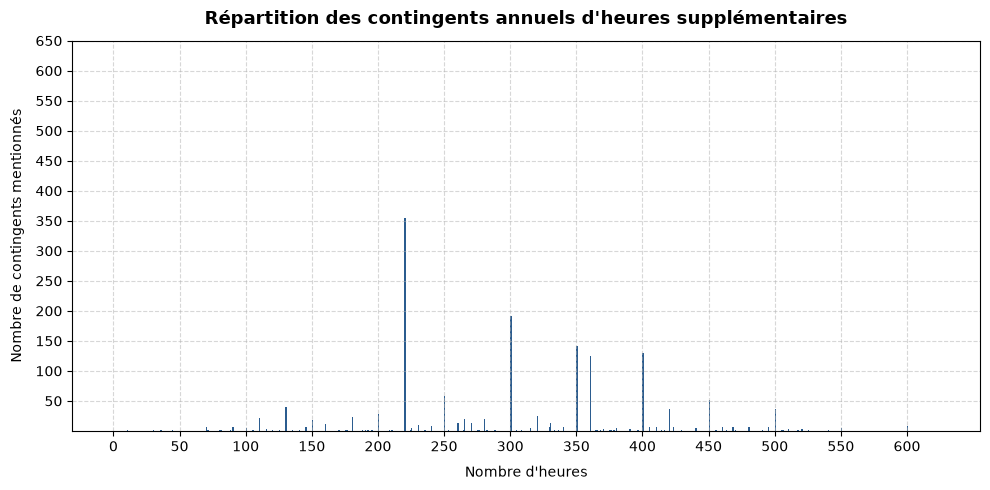

In [38]:
distrib_contingent(extraction_developped)

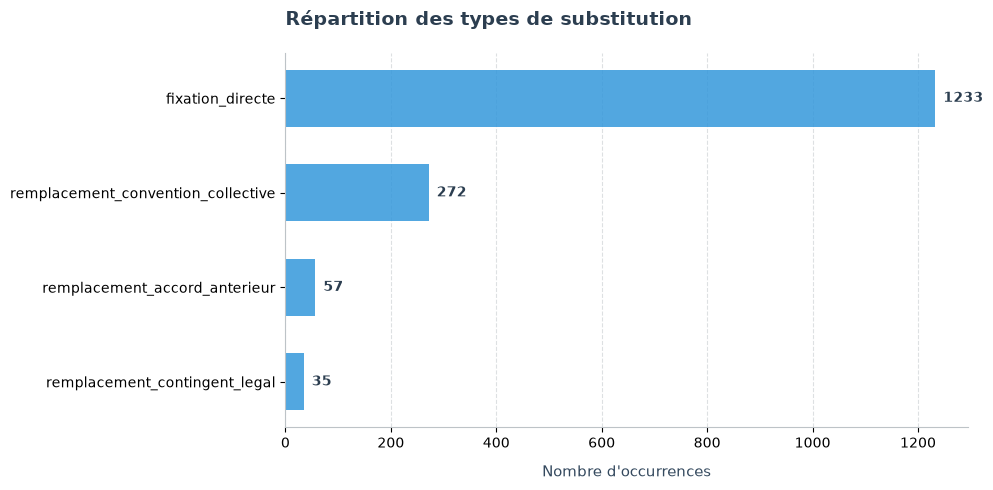

In [39]:
distrib_type_substitution(extraction_developped)

### 2021

In [175]:
extraction, extraction_evo, metadata = fetch_data(2021)

In [176]:
extraction_filtered, removed_anon = treat_extraction(extraction, extraction_evo)

Nombre d'erreurs dans extraction: 0/3057
Nombre d'erreurs dans extraction_evo: 0/3057
Nombre de contingents mesurés dans extraction: 1767
Nombre de contingents mesurés dans extraction_evo: 1772
Nombre d'observations différentes sur la présence d'un contingent: 201
131 observations filtrées:
      - 98 fixent un accord tiré d'un autre texte légal
      - 10 ont une donnée manquante qui a été interprétée comme présente par Qwen
      - 23 rappellent un contingent sans le fixer dans l'accord
      
Citation des extraits supposés anonymisés :
0. Conformément à l'article L.3121-33 du Code du travail, le contingent annuel d'heures supplémentaires est fixé à [blank] heures par salarié sur la période courant du 01er juin N au 31 Mai N+1.
1. Le contingent annuel d’heures supplémentaires librement utilisable est fixé à XXXX heures.
2. Le volume du contingent annuel d'heures est fixé par le présent accord collectif. [...] Cet accord d'entreprise relatif au contingent annuel prime sur l’accord de 

In [177]:
extraction_filtered = add_correct_references(extraction_filtered, extraction_evo, [removed_anon[i] for i in [5,7,9]])

In [178]:
with fs.open("s3://mateomorin/legifrance/extraction/contingent_evolution/year=2021/anonymised_ref.txt", "w") as f:
    f.write("\n".join([removed_anon[i] for i in [5,7,9]]))

In [45]:
extraction_developped = develop_contingents(extraction_filtered)

Taille iniale : 1742
Taille finale : 1810


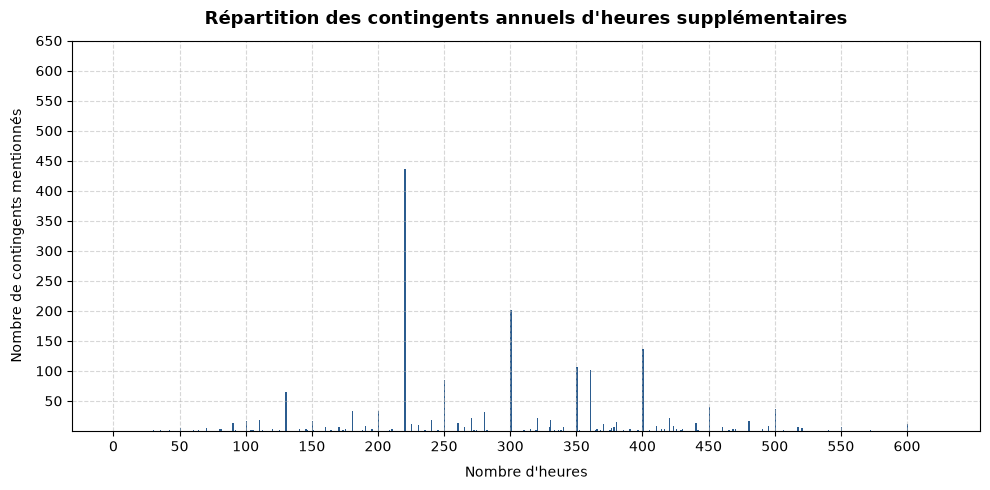

In [46]:
distrib_contingent(extraction_developped)

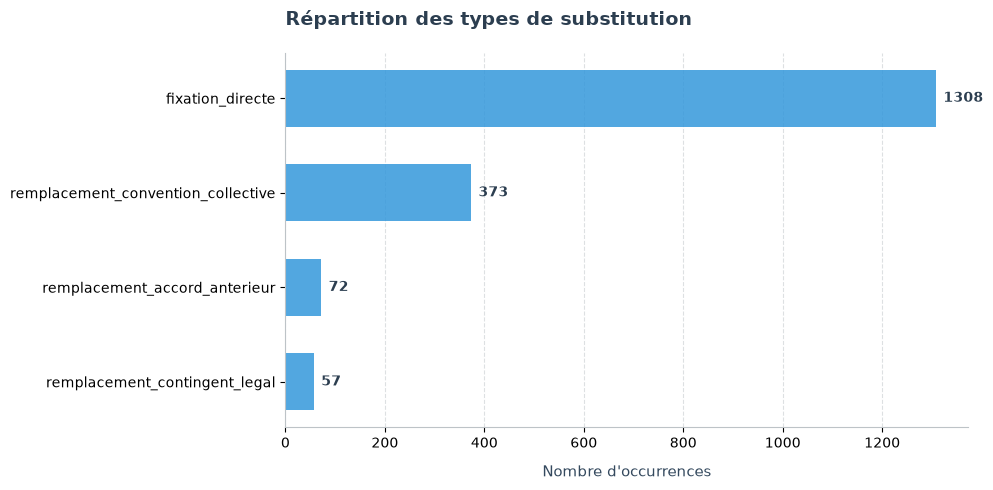

In [47]:
distrib_type_substitution(extraction_developped)

### 2022

In [169]:
extraction, extraction_evo, metadata = fetch_data(2022)

In [170]:
extraction_filtered, removed_anon = treat_extraction(extraction, extraction_evo)

Nombre d'erreurs dans extraction: 0/3185
Nombre d'erreurs dans extraction_evo: 0/3185
Nombre de contingents mesurés dans extraction: 1908
Nombre de contingents mesurés dans extraction_evo: 1907
Nombre d'observations différentes sur la présence d'un contingent: 187
116 observations filtrées:
      - 94 fixent un accord tiré d'un autre texte légal
      - 7 ont une donnée manquante qui a été interprétée comme présente par Qwen
      - 15 rappellent un contingent sans le fixer dans l'accord
      
Citation des extraits supposés anonymisés :
0. D’un commun accord et pour l’année 2023, le contingent annuel d’heures supplémentaires est porté à XXX heures.
1. Par dérogation aux dispositions de l’article 3-13 de la Convention Collective Nationale des Ouvriers du Bâtiment (IDCC 1596), et conformément aux dispositions de l’article L. 3121-33 du Code du Travail, le contingent d’heures supplémentaires est fixé à trois cent quatre-vingt (380) heures par année civile.
2. Par dérogation aux dispositi

In [171]:
extraction_filtered = add_correct_references(extraction_filtered, extraction_evo, [removed_anon[i] for i in [1, 2, 3]])

In [174]:
with fs.open("s3://mateomorin/legifrance/extraction/contingent_evolution/year=2022/anonymised_ref.txt", "w") as f:
    f.write("\n".join([removed_anon[i] for i in [1, 2, 3]]))

In [51]:
extraction_developped = develop_contingents(extraction_filtered)

Taille iniale : 1888
Taille finale : 1931


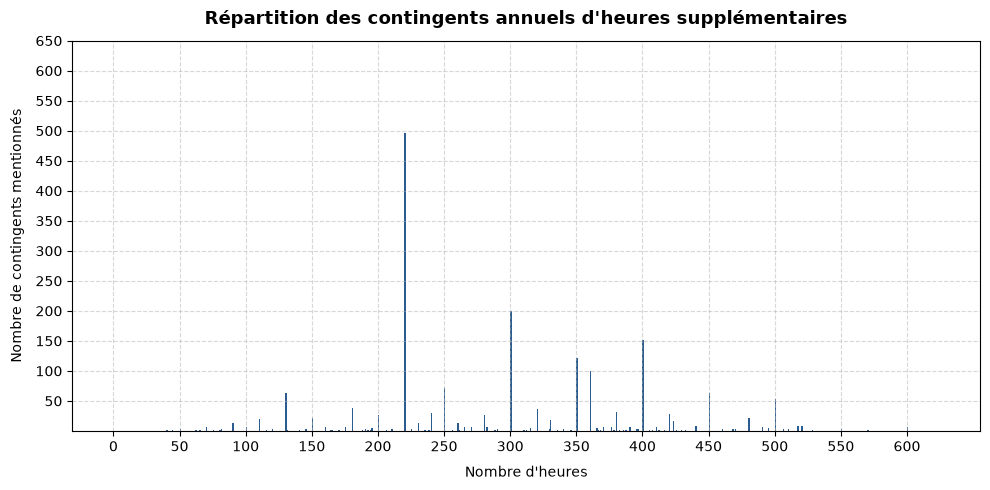

In [52]:
distrib_contingent(extraction_developped)

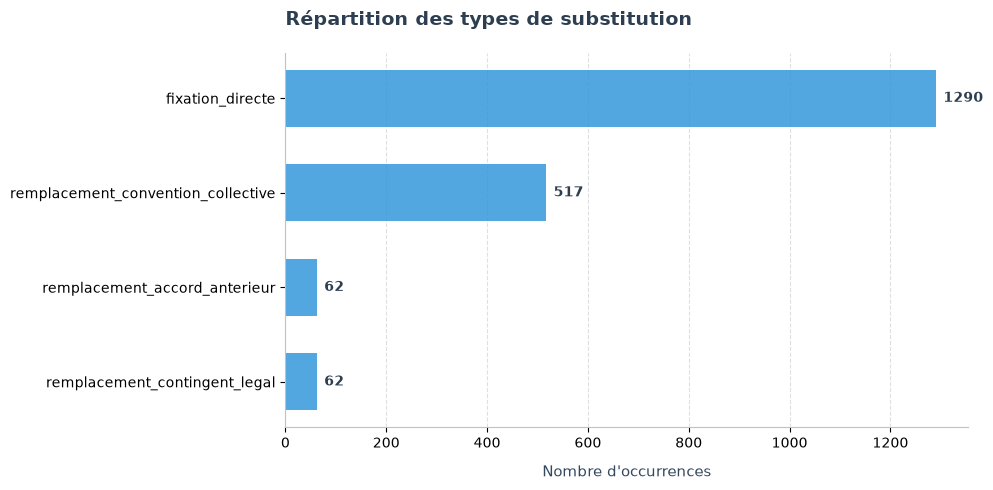

In [53]:
distrib_type_substitution(extraction_developped)

### 2023

In [179]:
extraction, extraction_evo, metadata = fetch_data(2023)

In [180]:
extraction_filtered, removed_anon = treat_extraction(extraction, extraction_evo)

Nombre d'erreurs dans extraction: 0/3590
Nombre d'erreurs dans extraction_evo: 0/3590
Nombre de contingents mesurés dans extraction: 2101
Nombre de contingents mesurés dans extraction_evo: 2132
Nombre d'observations différentes sur la présence d'un contingent: 279
153 observations filtrées:
      - 124 fixent un accord tiré d'un autre texte légal
      - 8 ont une donnée manquante qui a été interprétée comme présente par Qwen
      - 21 rappellent un contingent sans le fixer dans l'accord
      
Citation des extraits supposés anonymisés :
0. Par dérogation aux dispositions de la Convention collective nationale des ouvriers du Bâtiment de champagne Ardennes (IDCC 1596), de la convention collective des ETAM du Bâtiment (IDCC 2609) et de la convention collective des Cadres du Bâtiment (IDCC 2420) et conformément aux dispositions de l’article L. 3121-33 du Code du Travail, le contingent d’heures supplémentaires est fixé à quatre cent heures (400) heures par année civile et par salarié.
1. 

In [181]:
extraction_filtered = add_correct_references(extraction_filtered, extraction_evo, removed_anon[:5] + removed_anon[6:])

In [182]:
with fs.open("s3://mateomorin/legifrance/extraction/contingent_evolution/year=2023/anonymised_ref.txt", "w") as f:
    f.write("\n".join(removed_anon[:5] + removed_anon[6:]))

In [57]:
extraction_developped = develop_contingents(extraction_filtered)

Taille iniale : 2110
Taille finale : 2177


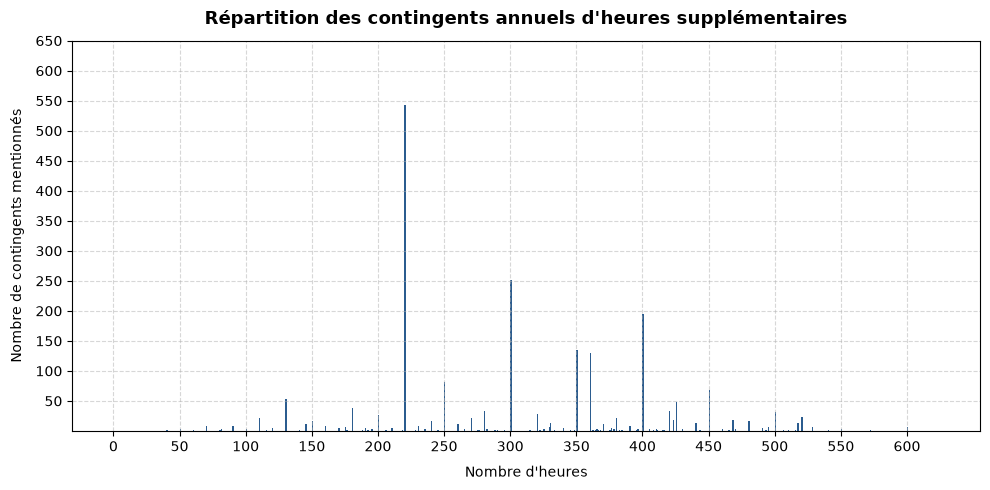

In [58]:
distrib_contingent(extraction_developped)

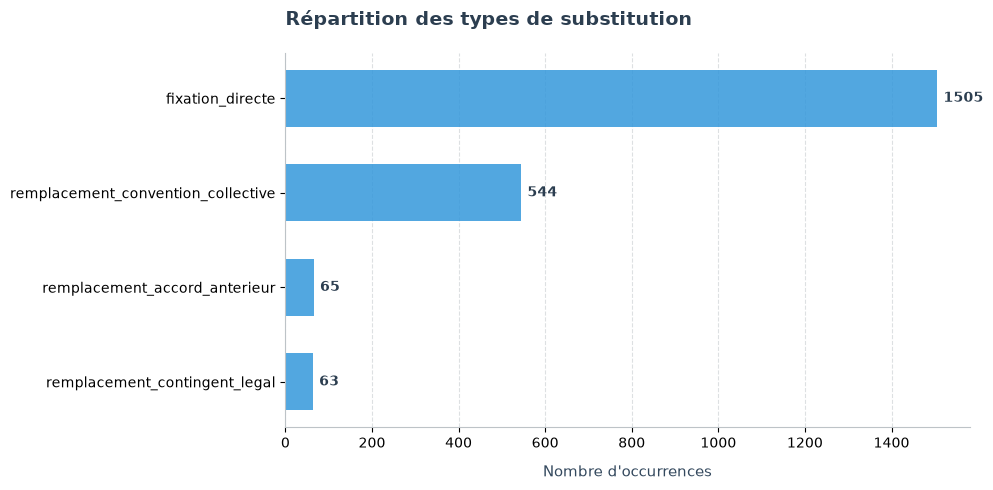

In [59]:
distrib_type_substitution(extraction_developped)

### 2024

In [192]:
extraction, extraction_evo, metadata = fetch_data(2024)

In [193]:
extraction_filtered, removed_anon = treat_extraction(extraction, extraction_evo)

Nombre d'erreurs dans extraction: 0/3805
Nombre d'erreurs dans extraction_evo: 0/3805
Nombre de contingents mesurés dans extraction: 2203
Nombre de contingents mesurés dans extraction_evo: 2182
Nombre d'observations différentes sur la présence d'un contingent: 203
132 observations filtrées:
      - 112 fixent un accord tiré d'un autre texte légal
      - 6 ont une donnée manquante qui a été interprétée comme présente par Qwen
      - 15 rappellent un contingent sans le fixer dans l'accord
      
Citation des extraits supposés anonymisés :
0. Le contingent annuel d’heures supplémentaires s’élève à  **heures. Le contingent s’applique par salarié, par année civile.
1. Par le présent accord d’entreprise, les parties conviennent de porter ce contingent à 300 heures par an et par salarié.
2. Le contingent annuel d’heures supplémentaires est fixé à 400 heures par an.
3. Les heures supplémentaires sont accomplies dans la limite d’un contingent annuel légal de 350 heures par période de référenc

In [194]:
extraction_filtered = add_correct_references(extraction_filtered, extraction_evo, removed_anon[1:4])

In [195]:
with fs.open("s3://mateomorin/legifrance/extraction/contingent_evolution/year=2024/anonymised_ref.txt", "w") as f:
    f.write("\n".join(removed_anon[1:4]))

In [126]:
extraction_developped = develop_contingents(extraction_filtered)

Taille iniale : 2165
Taille finale : 2224


In [127]:
isinstance(extraction.dtypes["contingents"], pd.StringDtype)

True

In [128]:
dfevo = extraction_developped.drop_duplicates("reference", keep=False)
df = develop_contingents(extraction).drop_duplicates("reference", keep=False)

Taille iniale : 3805
Taille finale : 3936


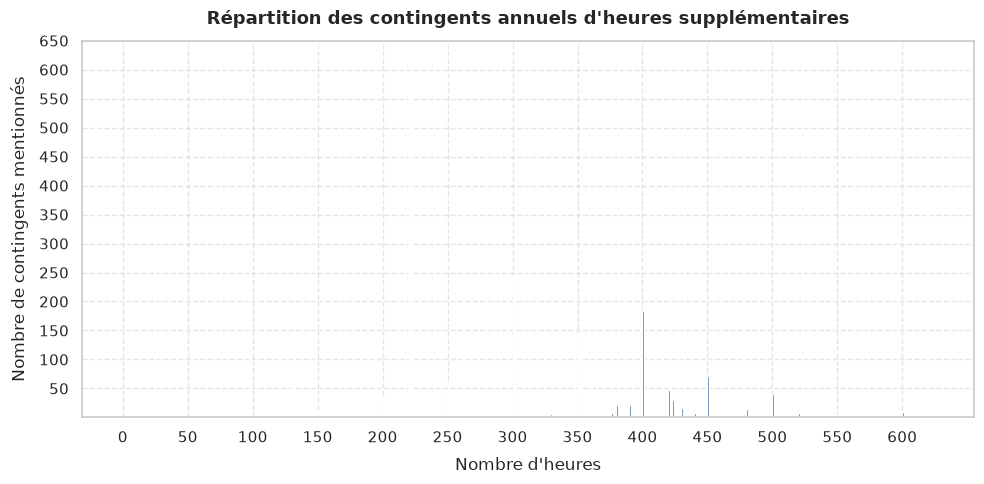

In [129]:
distrib_contingent(extraction_developped)

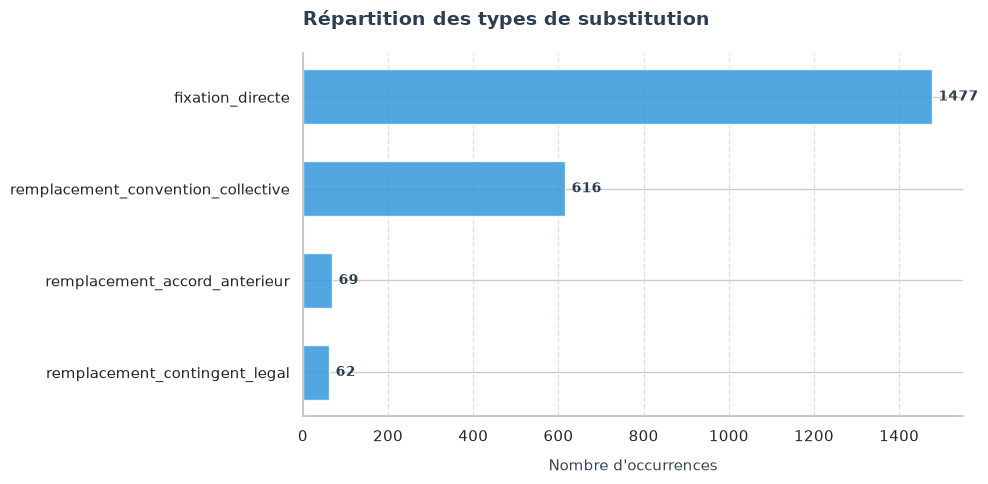

In [130]:
distrib_type_substitution(extraction_developped)

### Mini-comparaison entre les résultats

In [131]:
joined_df = dfevo.merge(df, how="inner", on="reference", suffixes=["_evo", ""])

In [133]:
joined_df = joined_df[pd.col("presence_contingent_conventionnel_evo") & pd.col("presence_contingent_conventionnel")]
joined_df = joined_df[pd.col("nombre_heures_fixe") != pd.col("nombre_heures")]

- T06724061004 : la conversion float int enlève la virgule en faisant *100
- T07824062295 : les deux LLMs ont tort, mais c'est compliqué de deviner ce qui se passe
- T08524061291 : Hallucination LLM

### 2025

In [187]:
extraction, extraction_evo, metadata = fetch_data(2025)

In [188]:
extraction_filtered, removed_anon = treat_extraction(extraction, extraction_evo)

Nombre d'erreurs dans extraction: 0/3609
Nombre d'erreurs dans extraction_evo: 0/3609
Nombre de contingents mesurés dans extraction: 2116
Nombre de contingents mesurés dans extraction_evo: 2124
Nombre d'observations différentes sur la présence d'un contingent: 196
118 observations filtrées:
      - 94 fixent un accord tiré d'un autre texte légal
      - 10 ont une donnée manquante qui a été interprétée comme présente par Qwen
      - 14 rappellent un contingent sans le fixer dans l'accord
      
Citation des extraits supposés anonymisés :
0. À ce titre, il est expressément convenu que le contingent annuel d’heures supplémentaires applicable à l’Entreprise est le contingent légal, énoncé à l’article D.3121-24 du code du travail. [...] de sorte que chaque nouvel embauché dispose, dès son entrée dans la société et quelle qu’en soit la date, d’un contingent annuel de 220 heures supplémentaires
1. Dans le cadre du présent accord collectif, il est défini que le contingent annuel d'heures sup

In [189]:
extraction_filtered = add_correct_references(extraction_filtered, extraction_evo, [removed_anon[i] for i in [0, 1, 3, 4, 6, 7, 8, 9]])

In [191]:
with fs.open("s3://mateomorin/legifrance/extraction/contingent_evolution/year=2025/anonymised_ref.txt", "w") as f:
    f.write("\n".join([removed_anon[i] for i in [0, 1, 3, 4, 6, 7, 8, 9]]))

In [78]:
extraction_developped = develop_contingents(extraction_filtered)

Taille iniale : 2108
Taille finale : 2161


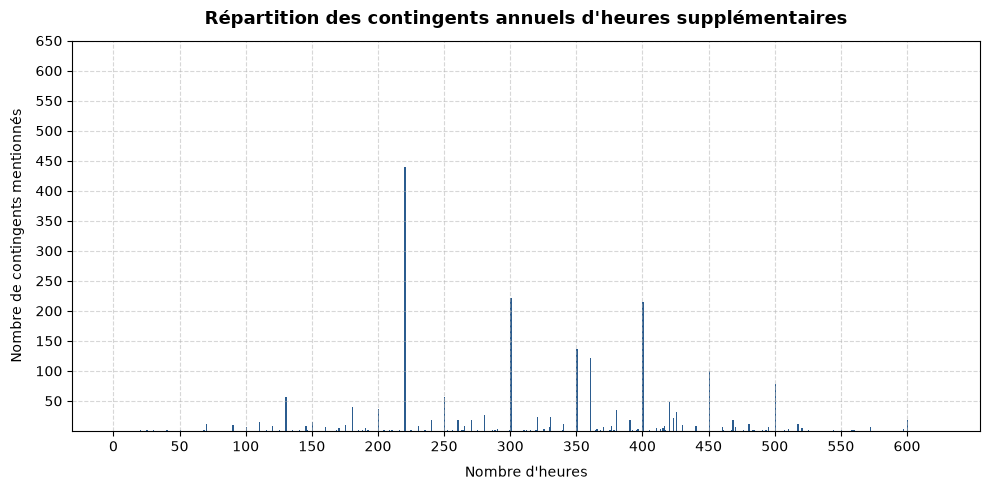

In [79]:
distrib_contingent(extraction_developped)

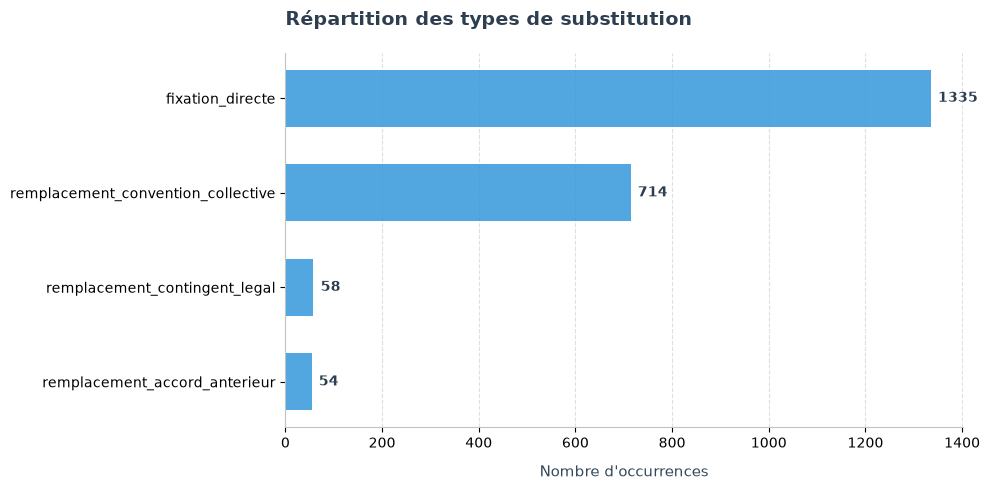

In [80]:
distrib_type_substitution(extraction_developped)

# Visualisation globale

In [196]:
def fetch_all_years():
    extraction_all = []
    extraction_evo_all = []
    metadata_all = []

    for year in range(2018, 2026):
        extraction, extraction_evo, metadata = fetch_data(year)
        extraction_all.append(extraction)
        extraction_evo_all.append(extraction_evo)
        metadata_all.append(metadata)

    extraction = pd.concat(extraction_all)
    extraction_evo = pd.concat(extraction_evo_all)
    metadata = pd.concat(metadata_all)

    return extraction, extraction_evo, metadata

In [209]:
extraction, extraction_evo, metadata = fetch_all_years()

In [212]:
def treat_all_years(extraction, extraction_evo):
    print(f"Nombre d'erreurs dans extraction: {extraction['erreur'].count()}/{len(extraction)}")
    print(f"Nombre d'erreurs dans extraction_evo: {extraction_evo['erreur'].count()}/{len(extraction)}")
    extraction = extraction[pd.col("erreur").isna()]
    extraction_evo = extraction_evo[pd.col("erreur").isna()]

    compare_extraction = extraction_evo.merge(extraction, on="reference", how="inner", suffixes=["_evo", ""])

    mask_presence = pd.col("presence_contingent_conventionnel_evo") | pd.col("presence_contingent_conventionnel")
    compare_extraction = compare_extraction[mask_presence]

    mask_mismatch = pd.col("presence_contingent_conventionnel_evo") ^ pd.col("presence_contingent_conventionnel")
    mismatches = compare_extraction[mask_mismatch]

    print(f"Nombre de contingents mesurés dans extraction: {compare_extraction['presence_contingent_conventionnel'].sum()}")
    print(f"Nombre de contingents mesurés dans extraction_evo: {compare_extraction['presence_contingent_conventionnel_evo'].sum()}")
    print(f"Nombre d'observations différentes sur la présence d'un contingent: {len(mismatches)}")

    # Removing data where the contingent is taken from another legal text
    removed_other_text = mismatches.loc[pd.col("presence_contingent_conventionnel"), "reference"].to_list()

    # Removing data that has been hidden
    with open("sources/noisy_data/accords_caches.txt") as f:
        removed_anon = f.read().split("\n")

    # Removing data that is most probably a recall from a legal text
    removed_recall = mismatches[pd.col("presence_contingent_conventionnel_evo")]
    removed_recall = removed_recall[pd.col("justification_ou_reserve").str.contains("rappel", na=False)]
    removed_recall = removed_recall["reference"].to_list()

    removed = list(set(removed_other_text + removed_anon + removed_recall))

    extraction_evo = extraction_evo[pd.col("presence_contingent_conventionnel")]
    extraction_filtered = extraction_evo[~pd.col("reference").isin(removed)]
    print(f"""{len(removed)} observations filtrées:
    - {len(removed_other_text)} fixent un accord tiré d'un autre texte légal
    - {len(removed_anon)} ont une donnée manquante qui a été interprétée comme présente par Qwen
    - {len(removed_recall)} rappellent un contingent sans le fixer dans l'accord
    """)

    # Developping mutliple contingents in a same accord
    extraction_developped = develop_contingents(extraction_filtered)

    # Changing data that is calculating contingent per month
    extraction_developped.loc[pd.col("periode").str.contains("mensuel"), "nombre_heures_fixe"] *= 12
    extraction_developped.loc[pd.col("periode").str.contains("mensuel"), "periode"] = "anuelle (montant à chaque mois x 12)"
    print(f"{len(extraction_developped[pd.col('periode') == "anuelle (montant à chaque mois x 12)"])} accords fixant un contingent mensuel.")

    return extraction_developped

In [216]:
extraction_developped = treat_all_years(extraction, extraction_evo)

Nombre d'erreurs dans extraction: 0/25174
Nombre d'erreurs dans extraction_evo: 0/25174
Nombre de contingents mesurés dans extraction: 14320
Nombre de contingents mesurés dans extraction_evo: 14294
Nombre d'observations différentes sur la présence d'un contingent: 1454
894 observations filtrées:
    - 740 fixent un accord tiré d'un autre texte légal
    - 23 ont une donnée manquante qui a été interprétée comme présente par Qwen
    - 131 rappellent un contingent sans le fixer dans l'accord
    
Taille iniale : 14140
Taille finale : 14560
8 accords fixant un contingent mensuel.


In [220]:
extraction_developped[pd.col("nombre_heures_fixe") > 600].value_counts("nombre_heures_fixe").sort_index()

nombre_heures_fixe
604      1
611      2
630      1
650      5
660      1
670      1
673      1
676      1
700      3
720      1
750      1
800      5
1000     5
1560     1
1582     1
1607     4
1743     1
1820     1
1947     5
2200     1
2400     1
3600     3
39996    3
52393    1
Name: count, dtype: int64

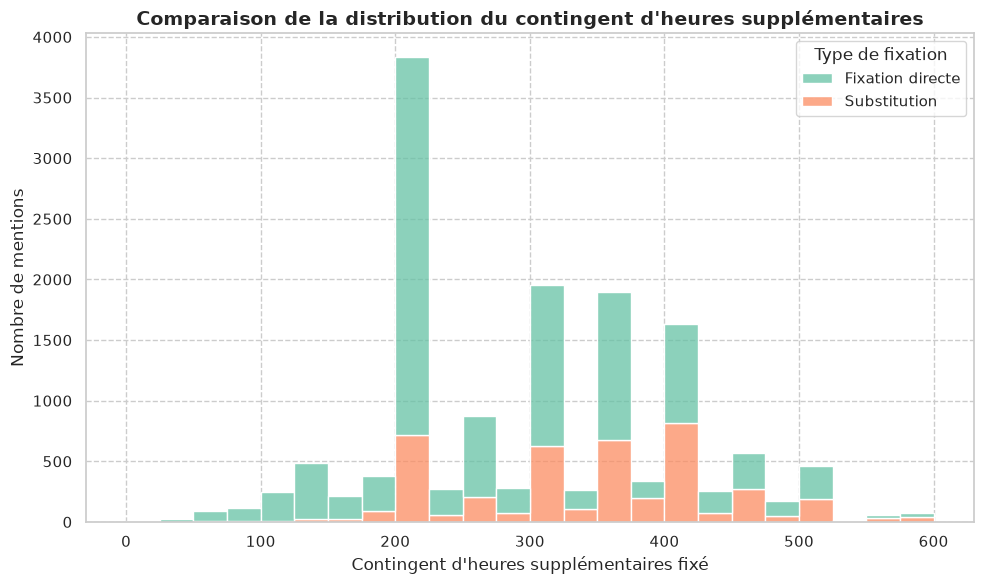

In [227]:
df_filtered = extraction_developped[
    extraction_developped["nombre_heures_fixe"] <= 600
]

df_filtered["Type de fixation"] = df_filtered["type_substitution"].apply(
    lambda x: "Fixation directe" if x == "fixation_directe" else "Substitution"
)
bins = range(0, 601, 25)

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df_filtered,
    x="nombre_heures_fixe",
    hue="Type de fixation",
    palette="Set2",
    bins=bins,
    multiple="stack"
)

plt.title(
    "Comparaison de la distribution du contingent d'heures supplémentaires",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Contingent d'heures supplémentaires fixé", fontsize=12)
plt.ylabel("Nombre de mentions", fontsize=12)
plt.grid(linestyle="--")

# Affichage
plt.tight_layout()
plt.show()

In [228]:
len(df_filtered[~pd.col("nombre_heures_avant_accord").isna()])

3205

In [229]:
df_filtered["diff_heures"] = df_filtered["nombre_heures_fixe"] - df_filtered["nombre_heures_avant_accord"]

Accords à diff_heures extrêmes

- T07824060903 : confond quota et contingent
- T04221004525 : inverse avant après
- T04922007015 : informations confuses
- T07422005892 : c'est presque pas du français, deux contingents mentionnés

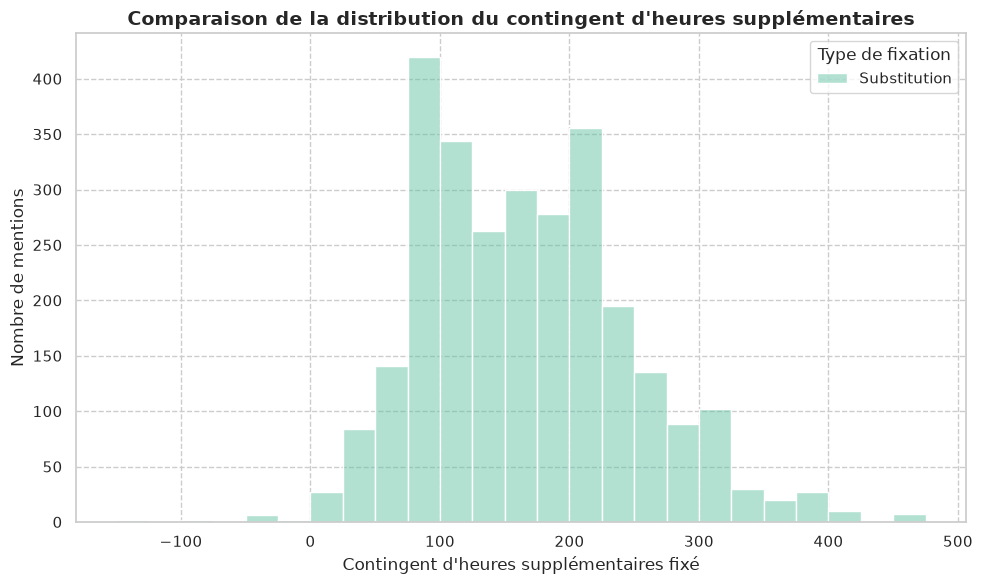

In [251]:
df_diff_heures = df_filtered.dropna(subset="diff_heures")[(pd.col("Type de fixation") == "Substitution") & (pd.col("diff_heures") >= -150)]
bins = range(-150, 500, 25)
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df_diff_heures,
    x="diff_heures",
    palette="Set2",
    hue="Type de fixation",
    bins=bins
)

plt.title(
    "Comparaison de la distribution du contingent d'heures supplémentaires",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Contingent d'heures supplémentaires fixé", fontsize=12)
plt.ylabel("Nombre de mentions", fontsize=12)
plt.grid(linestyle="--")

plt.tight_layout()
plt.show()

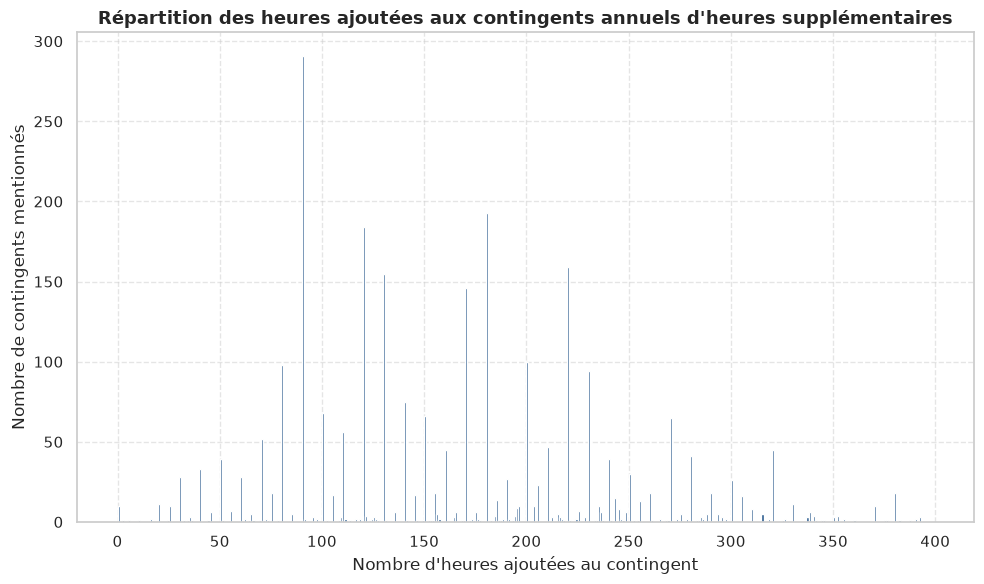

In [275]:
df_diff_heures = df_filtered.dropna(subset="diff_heures")[(pd.col("Type de fixation") == "Substitution") & (pd.col("diff_heures") >= -150)]
bins = range(0, 400, 1)
plt.figure(figsize=(10, 6))

df_diff_heures["diff_heures"].hist(
    bins=bins,
    color="#2b5c8f",
    grid=True,
    edgecolor=None,
)

plt.title("Répartition des heures ajoutées aux contingents annuels d'heures supplémentaires", fontsize=13, fontweight="bold")
plt.xlabel("Nombre d'heures ajoutées au contingent")
plt.ylabel("Nombre de contingents mentionnés")
plt.grid(alpha=0.5, linestyle="--")
plt.xticks(range(0, 425, 50))
plt.tight_layout()
plt.show()